# Probability Distributions in Machine Learning and Data Science
## Group 8 — Practical Demonstration Notebook

This notebook is split into two parts:
- **Part A**: Distribution Exploration — Gaussian distribution properties, sampling, and visualization
- **Part B**: Gaussian Naive Bayes Classifier — Building a classifier on synthetic data

Each cell is tagged with `📊 SLIDE X` to indicate which slide the output should be used in.

In [1]:
# Setup — imports used throughout
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Set consistent style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12
np.random.seed(42)

print('All libraries loaded successfully!')

All libraries loaded successfully!


---
# Part A: Distribution Exploration
---

### A1. Generating Gaussian Random Samples
📊 **SLIDE 13** — Histogram with theoretical overlay

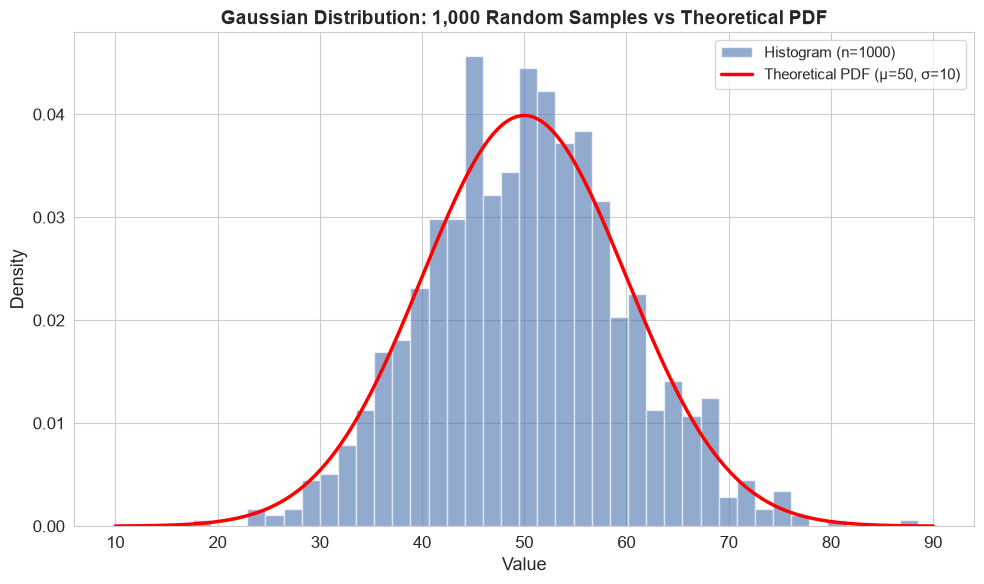

In [2]:
# Parameters for our Gaussian distribution
mu = 50        # True mean
sigma = 10     # True standard deviation
n_samples = 1000

# Generate random samples
samples = np.random.normal(loc=mu, scale=sigma, size=n_samples)

# Plot histogram with theoretical PDF overlay
fig, ax = plt.subplots(figsize=(10, 6))

# Histogram (density=True normalizes it to integrate to 1)
ax.hist(samples, bins=40, density=True, alpha=0.6, color='#4C72B0', 
        edgecolor='white', label=f'Histogram (n={n_samples})')

# Theoretical PDF overlay
x = np.linspace(mu - 4*sigma, mu + 4*sigma, 300)
pdf = stats.norm.pdf(x, loc=mu, scale=sigma)
ax.plot(x, pdf, 'r-', linewidth=2.5, label=f'Theoretical PDF (μ={mu}, σ={sigma})')

ax.set_xlabel('Value', fontsize=13)
ax.set_ylabel('Density', fontsize=13)
ax.set_title('Gaussian Distribution: 1,000 Random Samples vs Theoretical PDF', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('fig_histogram_overlay.png', dpi=150, bbox_inches='tight')
plt.show()

### A2. Sample vs Theoretical Statistics
📊 **SLIDE 13** — Comparison table

In [3]:
# Calculate sample statistics
sample_mean = np.mean(samples)
sample_var = np.var(samples, ddof=1)  # ddof=1 for unbiased estimate
sample_std = np.std(samples, ddof=1)

# Theoretical values
theo_mean = mu
theo_var = sigma**2
theo_std = sigma

print('=' * 55)
print(f'{"Statistic":<20} {"Theoretical":>12} {"Sample":>12} {"Difference":>12}')
print('=' * 55)
print(f'{"Mean":<20} {theo_mean:>12.4f} {sample_mean:>12.4f} {abs(theo_mean - sample_mean):>12.4f}')
print(f'{"Variance":<20} {theo_var:>12.4f} {sample_var:>12.4f} {abs(theo_var - sample_var):>12.4f}')
print(f'{"Std Deviation":<20} {theo_std:>12.4f} {sample_std:>12.4f} {abs(theo_std - sample_std):>12.4f}')
print('=' * 55)
print(f'\nInterpretation: With {n_samples} samples, the sample statistics')
print(f'closely match the theoretical values, demonstrating the')
print(f'Law of Large Numbers.')

Statistic             Theoretical       Sample   Difference
Mean                      50.0000      50.1933       0.1933
Variance                 100.0000      95.8864       4.1136
Std Deviation             10.0000       9.7922       0.2078

Interpretation: With 1000 samples, the sample statistics
closely match the theoretical values, demonstrating the
Law of Large Numbers.


### A3. Effect of Changing Parameters (μ and σ)
📊 **SLIDE 5** — Parameter variation plots

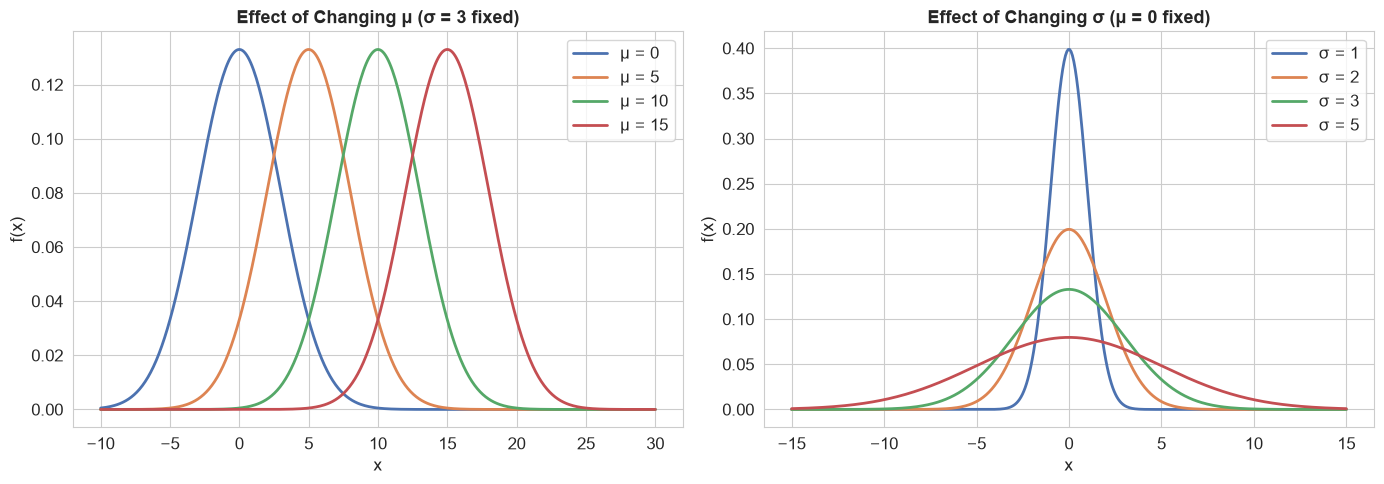

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left plot: Varying μ (mean) ---
x_range = np.linspace(-10, 30, 400)
for mean_val, color in zip([0, 5, 10, 15], ['#4C72B0', '#DD8452', '#55A868', '#C44E52']):
    pdf_vals = stats.norm.pdf(x_range, loc=mean_val, scale=3)
    axes[0].plot(x_range, pdf_vals, linewidth=2, label=f'μ = {mean_val}', color=color)

axes[0].set_title('Effect of Changing μ (σ = 3 fixed)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('x')
axes[0].set_ylabel('f(x)')
axes[0].legend()

# --- Right plot: Varying σ (std dev) ---
x_range = np.linspace(-15, 15, 400)
for std_val, color in zip([1, 2, 3, 5], ['#4C72B0', '#DD8452', '#55A868', '#C44E52']):
    pdf_vals = stats.norm.pdf(x_range, loc=0, scale=std_val)
    axes[1].plot(x_range, pdf_vals, linewidth=2, label=f'σ = {std_val}', color=color)

axes[1].set_title('Effect of Changing σ (μ = 0 fixed)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('x')
axes[1].set_ylabel('f(x)')
axes[1].legend()

plt.tight_layout()
plt.savefig('fig_parameter_effects.png', dpi=150, bbox_inches='tight')
plt.show()

### A4. CDF Plot
📊 **SLIDE 5** — CDF visualization

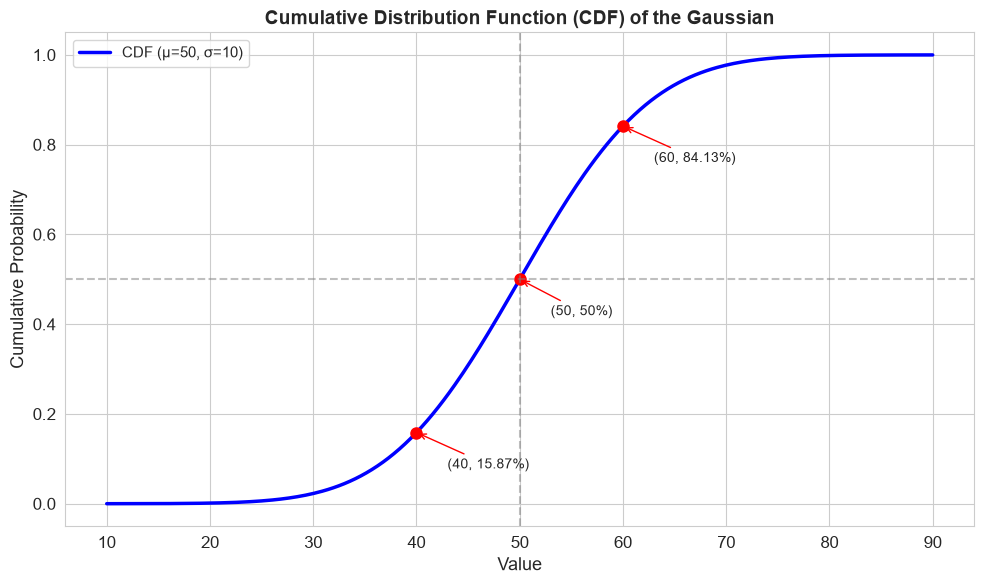

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 300)
cdf = stats.norm.cdf(x, loc=mu, scale=sigma)

ax.plot(x, cdf, 'b-', linewidth=2.5, label=f'CDF (μ={mu}, σ={sigma})')

# Mark key percentiles
for z, pct in zip([-1, 0, 1], ['15.87%', '50%', '84.13%']):
    x_val = mu + z * sigma
    y_val = stats.norm.cdf(x_val, loc=mu, scale=sigma)
    ax.plot(x_val, y_val, 'ro', markersize=8)
    ax.annotate(f'({x_val}, {pct})', xy=(x_val, y_val), 
                xytext=(x_val + 3, y_val - 0.08), fontsize=10,
                arrowprops=dict(arrowstyle='->', color='red'))

ax.set_xlabel('Value', fontsize=13)
ax.set_ylabel('Cumulative Probability', fontsize=13)
ax.set_title('Cumulative Distribution Function (CDF) of the Gaussian', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5)
ax.axvline(x=mu, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('fig_cdf.png', dpi=150, bbox_inches='tight')
plt.show()

### A5. The 68-95-99.7 Rule Visualization
📊 **SLIDE 3** — Empirical rule shaded bell curve

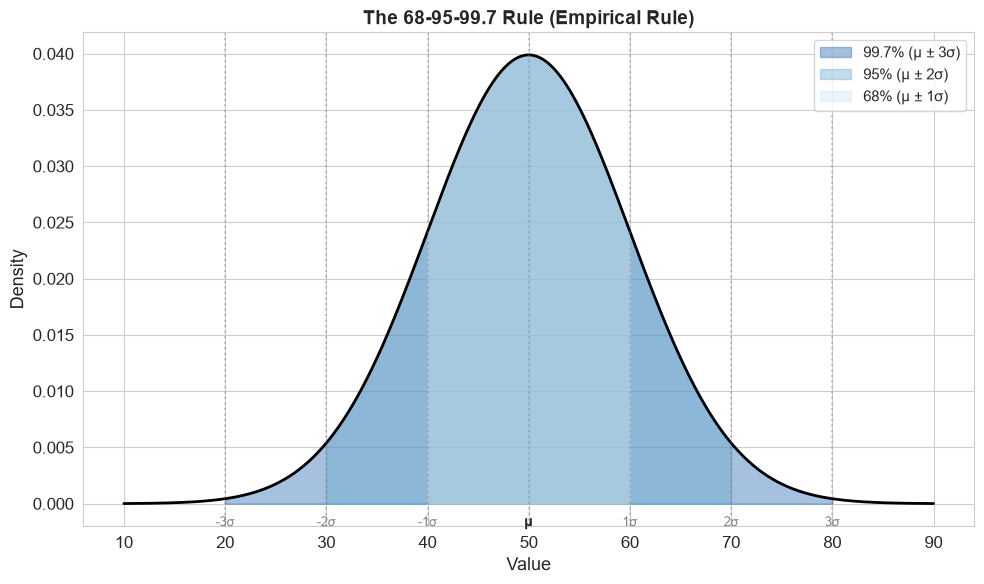

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

x = np.linspace(mu - 4*sigma, mu + 4*sigma, 500)
y = stats.norm.pdf(x, loc=mu, scale=sigma)
ax.plot(x, y, 'k-', linewidth=2)

# Shade regions
colors = ['#2166AC', '#67A9CF', '#D1E5F0']
labels = ['99.7% (μ ± 3σ)', '95% (μ ± 2σ)', '68% (μ ± 1σ)']
sigmas = [3, 2, 1]

for s, color, label in zip(sigmas, colors, labels):
    x_fill = np.linspace(mu - s*sigma, mu + s*sigma, 300)
    y_fill = stats.norm.pdf(x_fill, loc=mu, scale=sigma)
    ax.fill_between(x_fill, y_fill, alpha=0.4, color=color, label=label)

ax.set_xlabel('Value', fontsize=13)
ax.set_ylabel('Density', fontsize=13)
ax.set_title('The 68-95-99.7 Rule (Empirical Rule)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='upper right')

# Mark sigma positions
for s in [-3, -2, -1, 0, 1, 2, 3]:
    ax.axvline(x=mu + s*sigma, color='gray', linestyle=':', alpha=0.4)
    if s != 0:
        ax.text(mu + s*sigma, -0.002, f'{s}σ', ha='center', fontsize=9, color='gray')
    else:
        ax.text(mu, -0.002, 'μ', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('fig_empirical_rule.png', dpi=150, bbox_inches='tight')
plt.show()

### A6. Bernoulli Distribution Bar Plot
📊 **SLIDE 6** — Bernoulli visualization

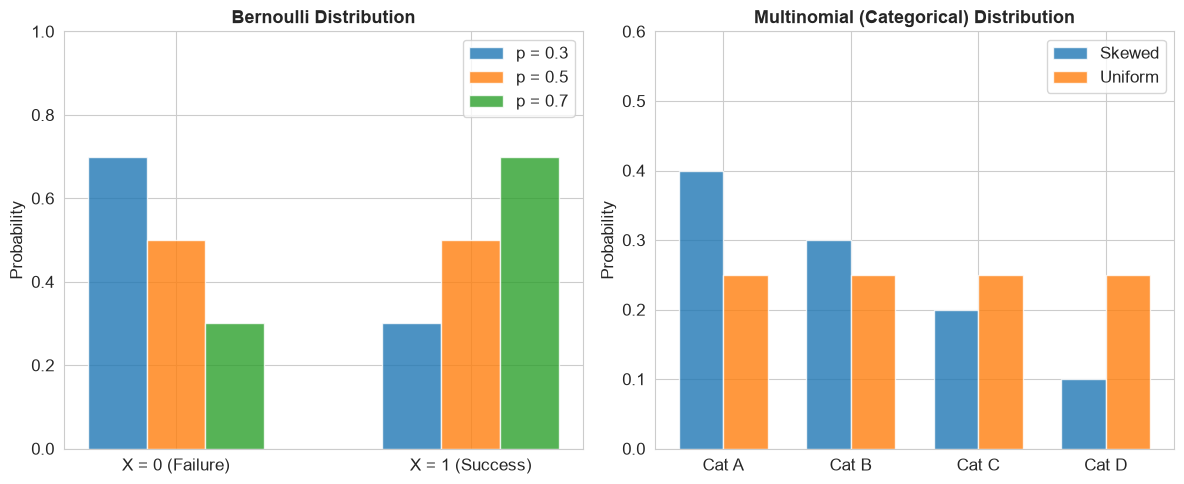

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Bernoulli Distribution ---
p_values = [0.3, 0.5, 0.7]
bar_width = 0.2
for i, p in enumerate(p_values):
    x_positions = np.array([0, 1]) + i * bar_width
    probs = [1 - p, p]
    axes[0].bar(x_positions, probs, width=bar_width, alpha=0.8, label=f'p = {p}')

axes[0].set_xticks([0 + bar_width, 1 + bar_width])
axes[0].set_xticklabels(['X = 0 (Failure)', 'X = 1 (Success)'])
axes[0].set_ylabel('Probability')
axes[0].set_title('Bernoulli Distribution', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].set_ylim(0, 1)

# --- Multinomial (shown as a single trial categorical distribution) ---
categories = ['Cat A', 'Cat B', 'Cat C', 'Cat D']
probs_set = [
    [0.4, 0.3, 0.2, 0.1],
    [0.25, 0.25, 0.25, 0.25],
]
labels_multi = ['Skewed', 'Uniform']
bar_width = 0.35
x_pos = np.arange(len(categories))

for i, (probs, lbl) in enumerate(zip(probs_set, labels_multi)):
    axes[1].bar(x_pos + i * bar_width, probs, width=bar_width, alpha=0.8, label=lbl)

axes[1].set_xticks(x_pos + bar_width / 2)
axes[1].set_xticklabels(categories)
axes[1].set_ylabel('Probability')
axes[1].set_title('Multinomial (Categorical) Distribution', fontsize=13, fontweight='bold')
axes[1].legend()
axes[1].set_ylim(0, 0.6)

plt.tight_layout()
plt.savefig('fig_bernoulli_multinomial.png', dpi=150, bbox_inches='tight')
plt.show()

---
# Part B: Gaussian Naive Bayes Classifier
---

### B1. Generate Synthetic Dataset
📊 **SLIDE 14** — Scatter plot of synthetic data

Total samples: 1000
Class 0: 500 samples | Class 1: 500 samples
Features: 2


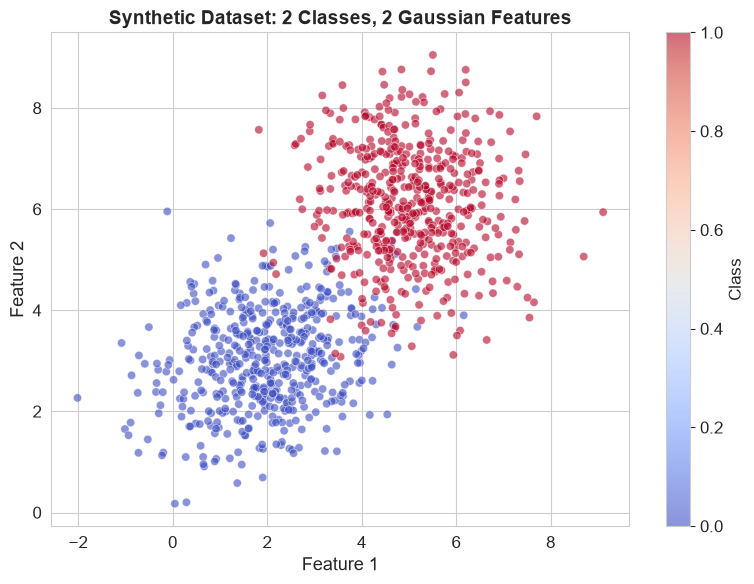

In [8]:
# Generate synthetic data: 2 classes, 2 features, each from a Gaussian
np.random.seed(42)

# Class 0: centered at (2, 3)
n_class0 = 500
X_class0 = np.random.multivariate_normal(
    mean=[2, 3], 
    cov=[[1.5, 0.3], [0.3, 1.0]], 
    size=n_class0
)

# Class 1: centered at (5, 6)
n_class1 = 500
X_class1 = np.random.multivariate_normal(
    mean=[5, 6], 
    cov=[[1.2, -0.2], [-0.2, 1.3]], 
    size=n_class1
)

# Combine
X = np.vstack([X_class0, X_class1])
y = np.array([0] * n_class0 + [1] * n_class1)

print(f'Total samples: {len(y)}')
print(f'Class 0: {n_class0} samples | Class 1: {n_class1} samples')
print(f'Features: {X.shape[1]}')

# Scatter plot
fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', alpha=0.6, edgecolors='w', linewidth=0.5)
ax.set_xlabel('Feature 1', fontsize=13)
ax.set_ylabel('Feature 2', fontsize=13)
ax.set_title('Synthetic Dataset: 2 Classes, 2 Gaussian Features', fontsize=14, fontweight='bold')
plt.colorbar(scatter, label='Class')
plt.tight_layout()
plt.savefig('fig_synthetic_data.png', dpi=150, bbox_inches='tight')
plt.show()

### B2. Feature Distributions per Class
📊 **SLIDE 8** — Overlapping Gaussians per feature

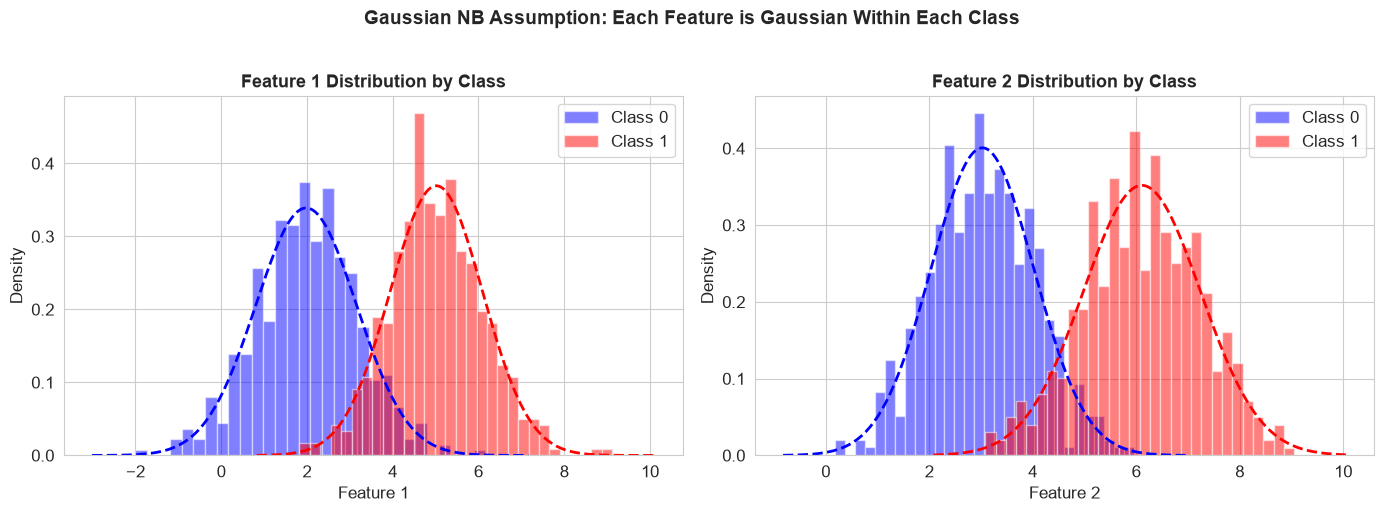

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

feature_names = ['Feature 1', 'Feature 2']
for i, ax in enumerate(axes):
    # Histogram for each class
    ax.hist(X[y == 0, i], bins=30, density=True, alpha=0.5, color='blue', label='Class 0')
    ax.hist(X[y == 1, i], bins=30, density=True, alpha=0.5, color='red', label='Class 1')
    
    # Fit and overlay Gaussians
    for cls, color in zip([0, 1], ['blue', 'red']):
        data = X[y == cls, i]
        mu_fit, sigma_fit = stats.norm.fit(data)
        x_range = np.linspace(data.min() - 1, data.max() + 1, 200)
        ax.plot(x_range, stats.norm.pdf(x_range, mu_fit, sigma_fit), 
                color=color, linewidth=2, linestyle='--')
    
    ax.set_title(f'{feature_names[i]} Distribution by Class', fontsize=13, fontweight='bold')
    ax.set_xlabel(feature_names[i])
    ax.set_ylabel('Density')
    ax.legend()

plt.suptitle('Gaussian NB Assumption: Each Feature is Gaussian Within Each Class', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig_feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

### B3. Train Gaussian Naive Bayes & Evaluate
📊 **SLIDE 14** — Accuracy, classification report, confusion matrix

In [10]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Train Gaussian NB
gnb = GaussianNB()
gnb.fit(X_train, y_train)

# Predict
y_pred = gnb.predict(X_test)

# Results
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.4f} ({accuracy*100:.1f}%)')
print(f'\nClassification Report:')
print(classification_report(y_test, y_pred, target_names=['Class 0', 'Class 1']))

# Learned parameters
print('Learned Parameters (MLE estimates):')
print(f'  Class 0 — μ: {gnb.theta_[0].round(3)}, σ²: {gnb.var_[0].round(3)}')
print(f'  Class 1 — μ: {gnb.theta_[1].round(3)}, σ²: {gnb.var_[1].round(3)}')

Accuracy: 0.9633 (96.3%)

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.97      0.95      0.96       150
     Class 1       0.95      0.97      0.96       150

    accuracy                           0.96       300
   macro avg       0.96      0.96      0.96       300
weighted avg       0.96      0.96      0.96       300

Learned Parameters (MLE estimates):
  Class 0 — μ: [2.006 3.04 ], σ²: [1.31  1.006]
  Class 1 — μ: [4.994 6.173], σ²: [1.168 1.375]


### B4. Confusion Matrix Heatmap
📊 **SLIDE 14** — Confusion matrix visualization

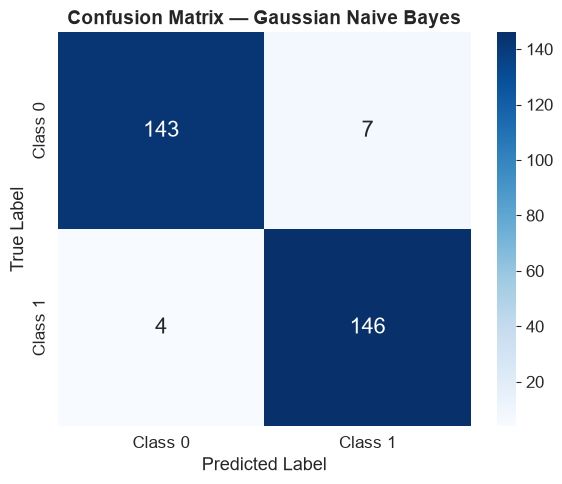

In [11]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'],
            annot_kws={'size': 16})
ax.set_xlabel('Predicted Label', fontsize=13)
ax.set_ylabel('True Label', fontsize=13)
ax.set_title('Confusion Matrix — Gaussian Naive Bayes', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### B5. Decision Boundary
📊 **SLIDE 14** — Decision boundary plot

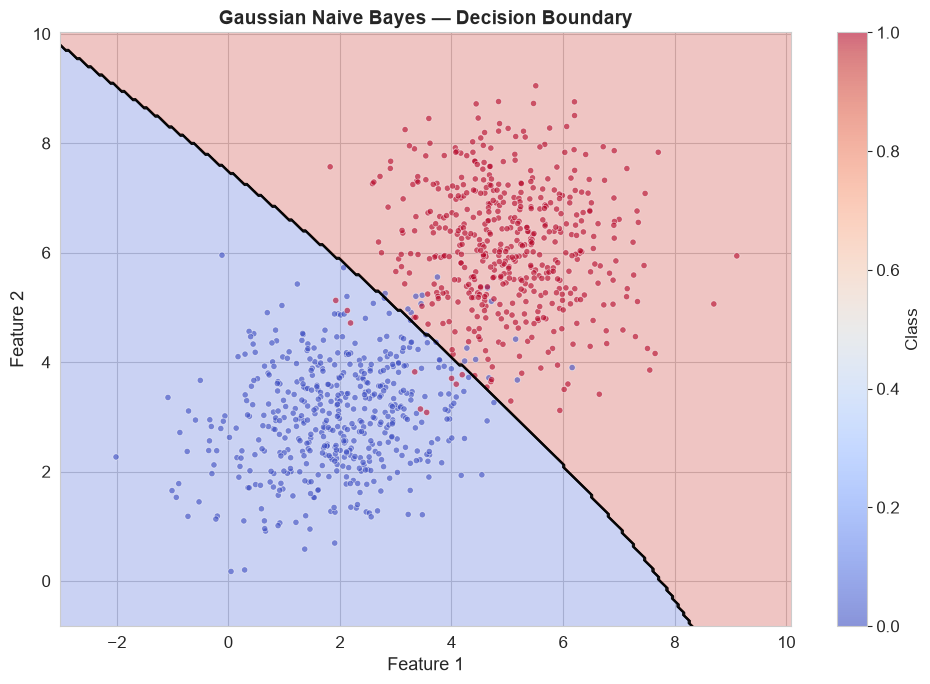


Interpretation:
The smooth curved boundary shows how GNB separates the classes.
Since the data genuinely comes from Gaussian distributions,
the model achieves high accuracy. The boundary is quadratic because
the two classes have different covariance structures.


In [12]:
# Create mesh grid for decision boundary
h = 0.05  # step size
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

# Predict on mesh
Z = gnb.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot
fig, ax = plt.subplots(figsize=(10, 7))
ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
ax.contour(xx, yy, Z, colors='k', linewidths=0.5)
scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', 
                     alpha=0.6, edgecolors='w', linewidth=0.5, s=20)

ax.set_xlabel('Feature 1', fontsize=13)
ax.set_ylabel('Feature 2', fontsize=13)
ax.set_title('Gaussian Naive Bayes — Decision Boundary', fontsize=14, fontweight='bold')
plt.colorbar(scatter, label='Class')
plt.tight_layout()
plt.savefig('fig_decision_boundary.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nInterpretation:')
print('The smooth curved boundary shows how GNB separates the classes.')
print('Since the data genuinely comes from Gaussian distributions,')
print('the model achieves high accuracy. The boundary is quadratic because')
print('the two classes have different covariance structures.')

### B6. Summary of Results
📊 **SLIDE 14** — Final interpretation

In [13]:
print('=' * 60)
print('           PRACTICAL DEMONSTRATION SUMMARY')
print('=' * 60)
print()
print('PART A — Distribution Exploration:')
print(f'  • Generated {n_samples} samples from N(μ={mu}, σ={sigma})')
print(f'  • Sample mean: {sample_mean:.4f} (theoretical: {mu})')
print(f'  • Sample variance: {sample_var:.4f} (theoretical: {sigma**2})')
print(f'  • Histogram closely matches theoretical PDF')
print()
print('PART B — Gaussian Naive Bayes Classifier:')
print(f'  • Synthetic dataset: {len(y)} samples, 2 classes, 2 features')
print(f'  • Train/Test split: 70% / 30%')
print(f'  • Test accuracy: {accuracy:.1%}')
print(f'  • GNB correctly learns the Gaussian parameters via MLE')
print(f'  • Decision boundary is smooth and effective')
print()
print('KEY TAKEAWAY:')
print('  When the Gaussian assumption holds, GNB is fast, simple,')
print('  and highly effective for classification tasks.')
print('=' * 60)

           PRACTICAL DEMONSTRATION SUMMARY

PART A — Distribution Exploration:
  • Generated 1000 samples from N(μ=50, σ=10)
  • Sample mean: 50.1933 (theoretical: 50)
  • Sample variance: 95.8864 (theoretical: 100)
  • Histogram closely matches theoretical PDF

PART B — Gaussian Naive Bayes Classifier:
  • Synthetic dataset: 1000 samples, 2 classes, 2 features
  • Train/Test split: 70% / 30%
  • Test accuracy: 96.3%
  • GNB correctly learns the Gaussian parameters via MLE
  • Decision boundary is smooth and effective

KEY TAKEAWAY:
  When the Gaussian assumption holds, GNB is fast, simple,
  and highly effective for classification tasks.
